<a href="https://colab.research.google.com/github/marvinjc/desarrollo_machine_learning/blob/main/desarrollo_machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [55]:
# Reúne las herramientas del ejercicio.
# Path y urllib obtienen la imagen; NumPy, PIL y KMeans la procesan.
from pathlib import Path
import urllib.request

import numpy as np
from PIL import Image
from sklearn.cluster import KMeans #Importamos KMeans, el modelo no supervisado

In [56]:
# Prepara la cantidad de colores, la URL de la imagen y las rutas de Colab.
# Crea las carpetas de entrada y de salida donde se guardan los archivos.
CANTIDAD_COLORES = 5
URL_IMAGEN = "https://raw.githubusercontent.com/marvinjc/desarrollo_machine_learning/main/pixel_art_720x720.png"

CARPETA = Path("/content/ejercicio_k-meas")
ENTRADA = CARPETA / "entrada"
SALIDA = CARPETA / "salida"

RUTA_IMAGEN = ENTRADA / "mosaico_cuadrado_de_colores.png"
RUTA_RESULTADO = SALIDA / "mosaico_5_colores.png"
RUTA_PALETA = SALIDA / "paleta.txt"

ENTRADA.mkdir(parents=True, exist_ok=True)
SALIDA.mkdir(parents=True, exist_ok=True)

In [57]:
# Descarga la imagen y la convierte en pixel art de 32x32.
# Cada píxel resume una zona de la foto original.
urllib.request.urlretrieve(URL_IMAGEN, RUTA_IMAGEN)

imagen = Image.open(RUTA_IMAGEN).convert("RGB")
imagen = imagen.resize((32, 32), Image.Resampling.BOX)
pixeles = np.array(imagen)
alto, ancho, canales = pixeles.shape

In [58]:
# K-Means agrupa los píxeles parecidos en la cantidad de colores indicada.
# Cada píxel se reemplaza por el color sólido de su grupo y se rearma la imagen.
colores = pixeles.reshape(-1, canales)

k_means = KMeans(n_clusters=CANTIDAD_COLORES, random_state=42, n_init=10)
etiquetas = k_means.fit_predict(colores)

paleta = k_means.cluster_centers_.astype(np.uint8)
colores_reducidos = paleta[etiquetas]
imagen_reducida = colores_reducidos.reshape(alto, ancho, canales)

/content/ejercicio_k-meas/salida/mosaico_5_colores.png
/content/ejercicio_k-meas/salida/paleta.txt


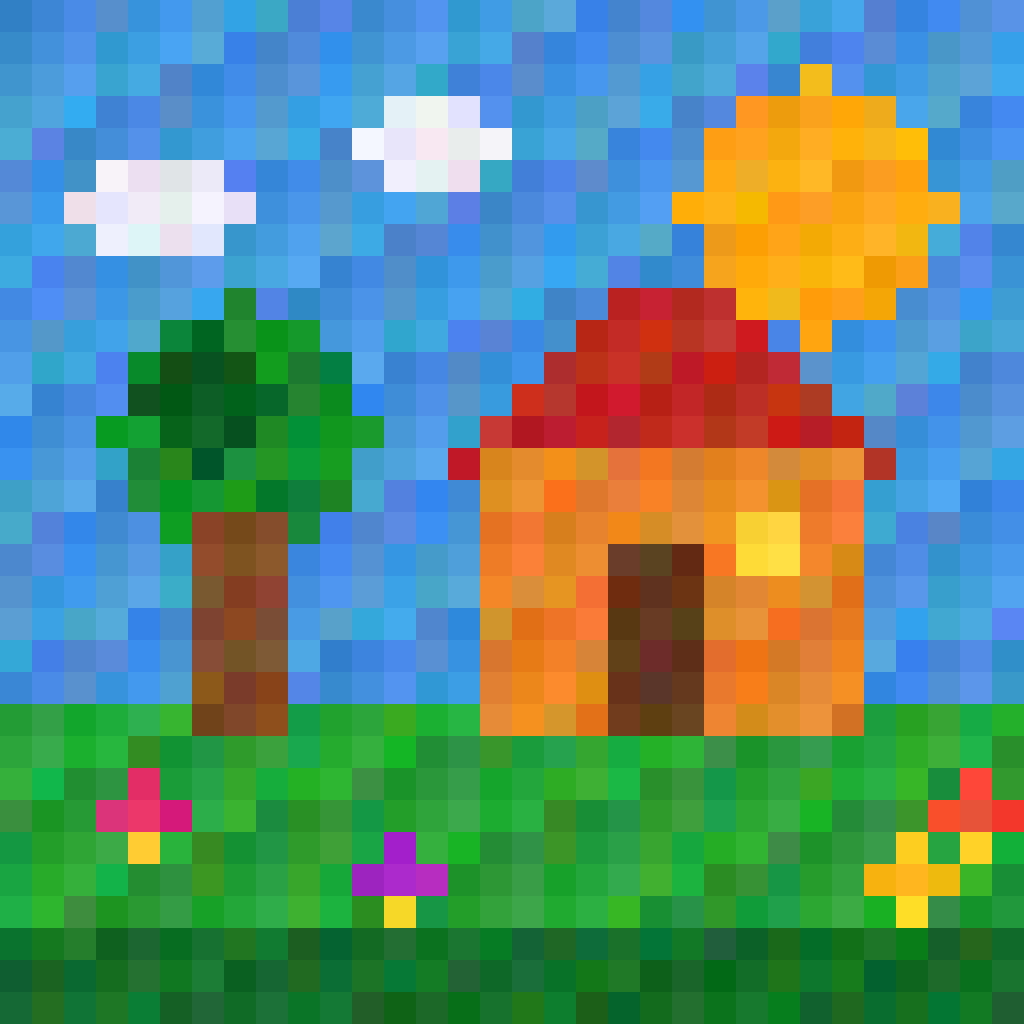

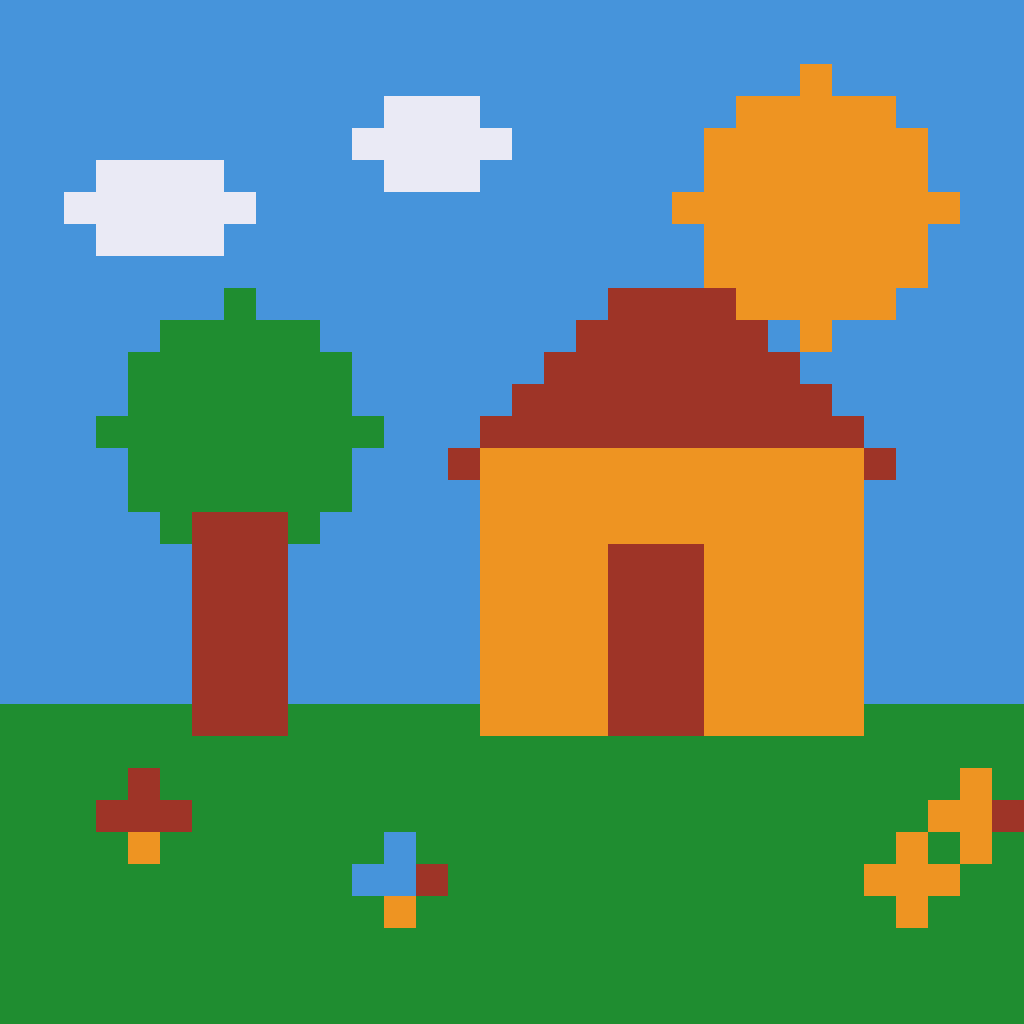

In [59]:
# Guarda la imagen reducida y la lista de colores sólidos en la carpeta de salida.
# Amplía la original y la reducida a 1024x1024 para compararlas en pantalla.
# Resultado real de K-Means, en 32x32
resultado = Image.fromarray(imagen_reducida)
resultado.save(RUTA_RESULTADO)

lineas = ["Colores solidos (RGB):"]
for indice, color in enumerate(paleta):
    rojo, verde, azul = (int(valor) for valor in color)
    lineas.append(f"{indice}: {rojo}, {verde}, {azul}")

RUTA_PALETA.write_text("\n".join(lineas), encoding="utf-8")

print(RUTA_RESULTADO)
print(RUTA_PALETA)

# Amplia cada pixel a un bloque solido de 32x32, sin mezclar colores
vista_original = imagen.resize((1024, 1024), Image.Resampling.NEAREST)
vista_reducida = resultado.resize((1024, 1024), Image.Resampling.NEAREST)

vista_original.save(SALIDA / "vista_original_1024.png")
vista_reducida.save(SALIDA / "vista_reducida_1024.png")

display(vista_original)
display(vista_reducida)